# What is a VAE, and what might it do with images?

This is one notebook in a series of three about VAEs:

1. [Synthetic image VAE (this notebook)](vae_cxr_synthetic.ipynb)
2. [ChestXray14 image VAE](vae_cxr_chestxray14.ipynb)
3. [EHR code-sequence VAE](../mortality_prediction/vae_ehr_timeseries.ipynb)

A variational autoencoder (VAE) learns a compact numerical summary of an image, then uses it to reconstruct the image. It can also sample a new summary to generate an image.

For example, an image VAE could be applied to chest X-ray images. PyHealth includes dataset loaders for `ChestXray14Dataset` and `COVID19CXRDataset`. `ChestXray14Dataset` can download its data when requested; `COVID19CXRDataset` reads a separately downloaded and extracted radiography dataset. This notebook uses synthetic drawings so it runs without either dataset, and its results do not show X-ray image quality.

For chest X-rays, researchers could explore using a VAE to:

- Initialize an image classifier with its encoder, then fine-tune it on labeled radiographs.
- Generate candidate images from sampled latent summaries.
- Compare images using distances between their latent summaries.

Each use needs its own evaluation. Reconstructions can lose subtle details, generated images may be unrealistic, and latent distances are not automatically a reliable similarity measure. This notebook demonstrates generation and comparison on synthetic drawings; it does not fine-tune a classifier or train on X-rays.

## Create a tiny synthetic dataset

To keep this notebook easy to run, we use 12 computer-generated grayscale ring drawings instead of loading chest X-rays. Their three pattern labels stand in for the kinds of classes a real image task might use; they are not clinical findings. Training and generating with these drawings demonstrates the workflow, not X-ray image quality.

In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw
import torch

from pyhealth.datasets import create_sample_dataset, get_dataloader
from pyhealth.models import VAE

image_dir = TemporaryDirectory()
samples = []
labels = ["pattern-a", "pattern-b", "pattern-c"]
for index in range(12):
    label = labels[index % len(labels)]
    pixels = np.full((32, 32), 35 + 45 * (index % 3), dtype=np.uint8)
    image = Image.fromarray(pixels)
    draw = ImageDraw.Draw(image)
    draw.ellipse((6 + index % 5, 8, 25, 27), outline=220, width=2)
    path = Path(image_dir.name) / f"image-{index}.png"
    image.save(path)
    samples.append({"image": str(path), "category": label})

dataset = create_sample_dataset(
    samples=samples,
    input_schema={"image": ("image", {"image_size": 32, "mode": "L"})},
    output_schema={"category": "multiclass"},
    dataset_name="vae-image-demo",
)
loader = get_dataloader(dataset, batch_size=4, shuffle=True, seed=7)
display_batch = next(iter(get_dataloader(dataset, batch_size=4, shuffle=False)))
print("Training images:", len(dataset))
print("Comparison batch:", display_batch["image"].shape)
print("Encoded labels:", display_batch["category"].tolist())

## Train once and save selected epoch snapshots

A short run can make a random-initialized VAE look like it has learned nothing. Here we train for 50 epochs and keep copies of the model weights after epochs 2, 10, 25, and 50. The optimizer continues throughout this single run, so each snapshot follows the previous one. PyTorch provides `state_dict()` and `load_state_dict()` for saving and restoring weights; the VAE does not need a special checkpoint-retrieval method. PyHealth's `Trainer` saves the latest or best checkpoint, but does not expose an every-epoch callback for this comparison, so this small example uses a straightforward PyTorch loop.

In [2]:
model = VAE(dataset, latent_dim=8, hidden_dim=4)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
checkpoint_epochs = {2, 10, 25, 50}
checkpoints = {}
epoch_losses = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
for epoch in range(1, 51):
    model.train()
    batch_losses = []
    for train_batch in loader:
        train_batch = {
            key: value.to(device) if torch.is_tensor(value) else value
            for key, value in train_batch.items()
        }
        optimizer.zero_grad()
        loss = model(**train_batch)["loss"]
        loss.backward()
        optimizer.step()
        batch_losses.append(float(loss.detach().cpu()))

    mean_loss = sum(batch_losses) / len(batch_losses)
    epoch_losses.append(mean_loss)
    if epoch in checkpoint_epochs:
        checkpoints[epoch] = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        print(f"Epoch {epoch:>2}: mean training objective = {mean_loss:.2f}")

Epoch  2: mean training objective = 747.80
Epoch 10: mean training objective = 733.53
Epoch 25: mean training objective = 646.61
Epoch 50: mean training objective = 619.61


## Compare reconstructions across training

Each row uses the same four input drawings. At each saved epoch we restore that epoch's weights and use the same random seed for latent sampling, making the comparison easier to read. More epochs help this tiny model begin to reproduce the simple rings, but the results remain blurry and inconsistent.

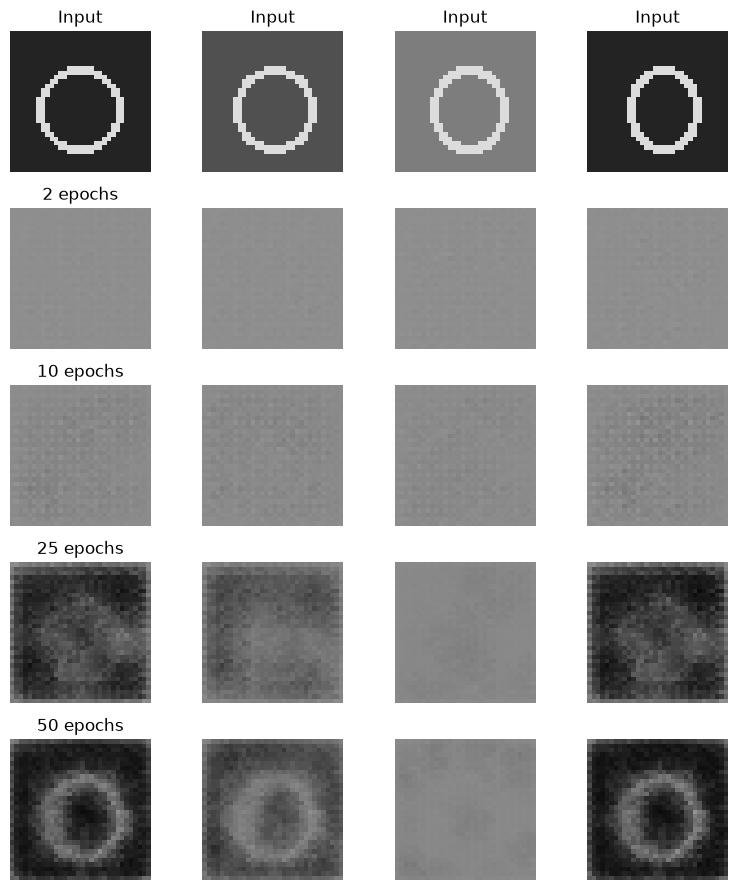

In [3]:
model.eval()
reconstructions = {}
for epoch, state in checkpoints.items():
    model.load_state_dict(state)
    torch.manual_seed(123)
    with torch.no_grad():
        batch = {
            key: value.to(device) if torch.is_tensor(value) else value
            for key, value in display_batch.items()
        }
        reconstructions[epoch] = model(**batch)["reconstruction"].cpu()

model.load_state_dict(checkpoints[50])
fig, axes = plt.subplots(5, 4, figsize=(8, 9))
for column in range(4):
    axes[0, column].imshow(
        display_batch["image"][column, 0], cmap="gray", vmin=0, vmax=1
    )
    axes[0, column].set_title("Input")
    axes[0, column].axis("off")
for row, epoch in enumerate((2, 10, 25, 50), start=1):
    for column in range(4):
        axes[row, column].imshow(
            reconstructions[epoch][column, 0], cmap="gray", vmin=0, vmax=1
        )
        axes[row, column].axis("off")
    axes[row, 0].set_title(f"{epoch} epochs")
plt.tight_layout()
plt.show()

## Generate images by synthetic class

`generate` accepts the encoded class indices learned by the fitted label processor. These are generated drawings associated with synthetic pattern labels, not radiographs.

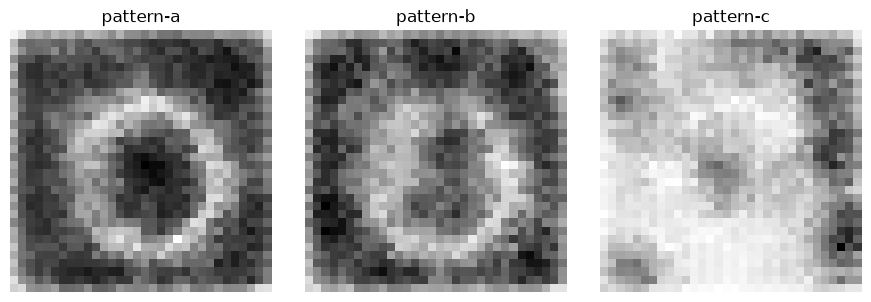

In [4]:
label_vocab = dataset.output_processors["category"].label_vocab
conditions = torch.tensor(list(label_vocab.values()))
model.eval()
with torch.no_grad():
    generated = model.generate(conditions=conditions)

fig, axes = plt.subplots(1, len(conditions), figsize=(9, 3))
for axis, (label, _), image in zip(axes, label_vocab.items(), generated):
    axis.imshow(image[0].cpu(), cmap="gray")
    axis.set_title(label)
    axis.axis("off")
plt.tight_layout()
plt.show()

## Compare images using their latent summaries

We compare one drawing with examples from the same and a different synthetic class using cosine similarity between latent summaries. This demonstrates the calculation; evaluating X-ray similarity would require real radiographs and meaningful reference judgments.

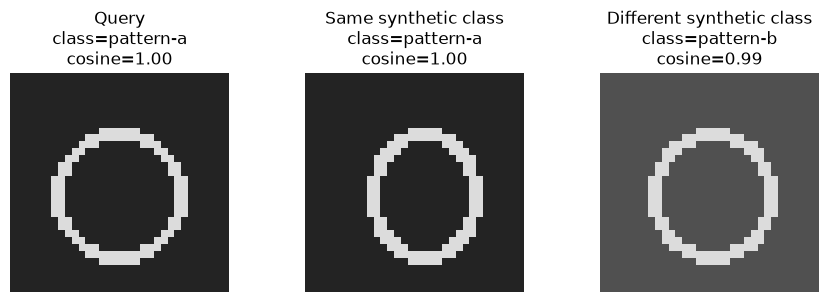

In [5]:
import torch.nn.functional as F

all_batch = next(
    iter(get_dataloader(dataset, batch_size=len(dataset), shuffle=False))
)
all_images = all_batch["image"].to(device)
all_labels = all_batch["category"].cpu()
with torch.no_grad():
    latent_means = model.image_mu(model.image_encoder(all_images))
    latent_means = F.normalize(latent_means, p=2, dim=1)

query_index = 0
same_class_index = next(
    index
    for index, label in enumerate(all_labels)
    if index != query_index and label == all_labels[query_index]
)
different_class_index = next(
    index
    for index, label in enumerate(all_labels)
    if label != all_labels[query_index]
)

pairs = [
    ("Query", query_index, 1.0),
    (
        "Same synthetic class",
        same_class_index,
        F.cosine_similarity(
            latent_means[query_index : query_index + 1],
            latent_means[same_class_index : same_class_index + 1],
        ).item(),
    ),
    (
        "Different synthetic class",
        different_class_index,
        F.cosine_similarity(
            latent_means[query_index : query_index + 1],
            latent_means[different_class_index : different_class_index + 1],
        ).item(),
    ),
]

label_by_id = {
    index: label
    for label, index in dataset.output_processors["category"].label_vocab.items()
}
fig, axes = plt.subplots(1, len(pairs), figsize=(9, 3))
for axis, (description, index, similarity) in zip(axes, pairs):
    axis.imshow(all_images[index, 0].cpu(), cmap="gray", vmin=0, vmax=1)
    axis.set_title(
        f"{description}\nclass={label_by_id[int(all_labels[index])]}\ncosine={similarity:.2f}"
    )
    axis.axis("off")
plt.tight_layout()
plt.show()